# Exploratory Data Analysis (EDA)
## Understanding, Cleaning, and Profiling Retail Customer Sales Data

**Project Overview**

This project performs Exploratory Data Analysis (EDA) on a retail customer sales dataset. The main aim is to inspect the raw data, identify and handle data-quality issues, explore patterns in customer and sales information, and derive useful business insights.

**Project Objectives**
- Understand the structure and quality of the dataset.
- Identify missing values, duplicate records, and invalid entries.
- Clean and prepare the data for analysis.
- Explore numerical and categorical variables using statistics and visualisations.
- Detect possible outliers and create useful derived features.
- Answer business questions using the cleaned dataset.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

print("EDA Project Started!")

EDA Project Started!


## 1. Importing Required Libraries

The following Python libraries are used in this project:

- **Pandas:** for loading, cleaning, and analysing tabular data.
- **NumPy:** for numerical operations and handling missing values.
- **Matplotlib and Seaborn:** for creating charts and visualisations.
- **Missingno:** for visual inspection of missing-value pattwrns.



In [2]:
df = pd.read_csv("../data/retail_customer_sales_dataset.csv")

df.head()

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.0,Male,62828.52,West,Gujarat,Surat,...,887.94,0.32,1811.40,1204.47,606.93,Debit Card,Standard,3.0,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.0,Male,50952.64,North,Haryana,Gurugram,...,14309.96,0.18,23468.33,17137.06,6331.27,Credit Card,Standard,3.0,High,No
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.0,Male,60476.00,East,Jharkhand,Ranchi,...,710.95,0.09,2587.86,1577.83,1010.03,Debit Card,Express,3.0,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.0,Male,41516.94,West,Gujarat,Surat,...,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.0,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.0,Female,95727.49,north,Haryana,Gurugram,...,10542.13,0.21,8328.28,5528.47,2799.81,UPI,Express,1.0,Low,No


## 2. Loading the Dataset

The retail customer sales data is loaded from a CSV file into a Pandas DataFrame. The first few records are displayed to confirm that the file has been read successfully.



In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (7084, 24)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7084 entries, 0 to 7083
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction_ID      7084 non-null   str    
 1   Customer_ID         7084 non-null   str    
 2   Order_Date          7084 non-null   str    
 3   Delivery_Date       6978 non-null   str    
 4   Age                 6942 non-null   float64
 5   Gender              7084 non-null   str    
 6   Income              6831 non-null   float64
 7   Region              7084 non-null   str    
 8   State               7084 non-null   str    
 9   City                7084 non-null   str    
 10  Customer_Segment    7084 non-null   str    
 11  Product_Category    7084 non-null   str    
 12  Product             7084 non-null   str    
 13  Quantity            7084 non-null   int64  
 14  Unit_Price          7084 non-null   float64
 15  Discount          

,Age,Income,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Customer_Rating
count,6942.000000,6.831000e+03,7084.00000,7084.000000,7013.000000,7084.000000,7084.000000,7084.000000,6656.000000
mean,36.234659,5.502381e+04,3.00847,4520.135232,0.200864,10942.867178,7360.466942,3582.400236,3.090595
std,15.735618,3.718343e+04,1.41129,4891.123919,0.121249,14504.750762,9849.348506,4912.636593,1.011457
min,-12.000000,1.500000e+04,1.00000,51.530000,-0.200000,28.700000,19.530000,9.170000,1.000000
25%,29.000000,3.705703e+04,2.00000,896.977500,0.110000,1816.572500,1214.417500,574.082500,2.000000
50%,36.000000,4.889751e+04,3.00000,2265.700000,0.180000,4835.195000,3233.080000,1530.365000,3.000000
75%,43.000000,6.539597e+04,4.00000,7224.157500,0.270000,14066.117500,9468.867500,4528.592500,4.000000
max,999.000000,1.750890e+06,10.00000,19989.990000,2.000000,122950.970000,81532.800000,47233.610000,5.000000


## 3. Initial Dataset Inspection

Before cleaning the data, we inspect its dimensions, column names, data types, and basic statistical summary. This gives an overview of the dataset and helps identify areas that may need further investigation.



In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check missing values percentage
print("\nMissing Values Percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
Transaction_ID          0
Customer_ID             0
Order_Date              0
Delivery_Date         106
Age                   142
Gender                  0
Income                253
Region                  0
State                   0
City                    0
Customer_Segment        0
Product_Category        0
Product                 0
Quantity                0
Unit_Price              0
Discount               71
Sales                   0
Cost                    0
Profit                  0
Payment_Method          0
Delivery_Mode           0
Customer_Rating       428
Satisfaction_Level    179
Returned                0
dtype: int64

Missing Values Percentage:
Transaction_ID        0.00
Customer_ID           0.00
Order_Date            0.00
Delivery_Date         1.50
Age                   2.00
Gender                0.00
Income                3.57
Region                0.00
State                 0.00
City                  0.00
Customer_Segment      0.00
Product_Category      

## 4. Identifying Duplicate Records

Duplicate records can affect the accuracy of analysis. In this section, we inspect exact duplicate rows and repeated transaction IDs to understand whether the dataset contains repwated entries.


In [5]:
# Display duplicate records
duplicates = df[df.duplicated()]

duplicates.head(10)

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
476,TXN202608,CUST10184,2023-02-09,2023-02-12,33.0,Female,50873.52,East,Odisha,Rourkela,...,13794.91,0.14,35590.87,28076.64,7514.23,Net Banking,Standard,4.0,High,No
1091,TXN200835,CUST10271,2024-08-22,2024-08-28,20.0,Female,44501.83,South,Kerala,Kochi,...,3695.19,0.09,6725.25,4857.88,1867.37,Credit Card,Standard,3.0,High,No
1375,TXN205342,CUST11294,2023-09-04,2023-09-07,36.0,Female,61618.71,South,Karnataka,Mysuru,...,882.28,0.12,1552.81,1180.08,372.73,Cash on Delivery,Same-Day,4.0,High,No
1376,TXN203048,CUST10017,2023-11-15,2023-11-25,39.0,Male,34950.71,West,Rajasthan,Udaipur,...,14806.11,0.21,23393.65,15819.14,7574.51,Net Banking,Standard,4.0,High,No
1383,TXN204970,CUST11582,2023-01-09,2023-01-15,24.0,Male,29832.35,East,Odisha,Rourkela,...,524.35,0.50,1048.70,607.69,441.01,UPI,Standard,3.0,Medium,No
1564,TXN205083,CUST11245,2024-04-28,2024-04-29,22.0,Male,29917.95,East,Jharkhand,Ranchi,...,6577.27,0.12,5788.00,3255.10,2532.90,Debit Card,Same-Day,4.0,High,No
1604,TXN203648,CUST10989,2023-05-15,2023-05-27,36.0,Male,47639.33,South,Andhra Pradesh,Vijayawada,...,3451.63,0.30,2416.14,1924.95,491.19,Debit Card,Standard,4.0,High,No
2339,TXN205465,CUST11191,2023-01-31,2023-02-06,21.0,Female,38145.37,North,Punjab,Ludhiana,...,676.47,0.47,2509.70,1546.36,963.34,Net Banking,Standard,3.0,Low,No
2392,TXN202535,CUST10297,2024-12-10,2024-12-17,39.0,Female,100648.67,East,West Bengal,Howrah,...,13212.91,0.17,32900.15,24427.61,8472.54,Credit Card,Same-Day,5.0,High,No
2803,TXN205070,CUST10257,2023-08-12,2023-08-22,28.0,Male,43803.94,West,Maharashtra,Nagpur,...,465.21,0.21,735.03,491.87,243.16,Debit Card,Standard,3.0,Medium,No


In [6]:
df["Transaction_ID"].duplicated().sum()

np.int64(84)

In [7]:
# Find rows having duplicate Transaction IDs
duplicate_ids = df[df["Transaction_ID"].duplicated(keep=False)]

# Sort and display duplicate IDs
duplicate_ids.sort_values("Transaction_ID").head(20)

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
6501,TXN200131,CUST11320,2023-05-09,2023-05-13,36.0,Male,35472.94,East,Odisha,Rourkela,...,398.45,0.33,1334.81,959.79,375.02,UPI,Express,2.0,Low,Yes
595,TXN200131,CUST11320,2023-05-09,2023-05-13,36.0,Male,35472.94,East,Odisha,Rourkela,...,398.45,0.33,1334.81,959.79,375.02,UPI,Express,2.0,Low,Yes
1386,TXN200162,CUST10126,2024-07-22,2024-07-26,25.0,Female,38515.52,South,Kerala,Thiruvananthapuram,...,2140.55,0.08,3938.61,2875.18,1063.43,Net Banking,Express,3.0,High,No
1227,TXN200162,CUST10126,22/07/2024,26/07/2024,25.0,Female,38515.52,South,Kerala,Thiruvananthapuram,...,2140.55,0.08,3938.61,2875.18,1063.43,Net Banking,Express,3.0,High,No
2905,TXN200213,CUST10481,2024-12-29,NaN,25.0,Male,64250.39,West,Goa,Vasco da Gama,...,2241.29,0.06,8427.25,5677.01,2750.24,Debit Card,Standard,3.0,Medium,No
5834,TXN200213,CUST10481,2024-12-29,NaN,25.0,Male,64250.39,West,Goa,Vasco da Gama,...,2241.29,0.06,8427.25,5677.01,2750.24,Debit Card,Standard,3.0,Medium,No
3392,TXN200221,CUST11154,2023-06-23,2023-06-29,54.0,female,47416.41,West,Rajasthan,Jaipur,...,1127.33,0.27,2468.85,1971.72,497.13,Cash on Delivery,Standard,3.0,NaN,No
6761,TXN200221,CUST11154,2023-06-23,2023-06-29,54.0,Female,47416.41,West,Rajasthan,Jaipur,...,1127.33,0.27,2468.85,1971.72,497.13,Cash on Delivery,Standard,3.0,NaN,No
1597,TXN200266,CUST11329,2024-12-20,2024-12-27,42.0,Female,76378.18,West,Goa,Vasco da Gama,...,919.74,0.32,2501.69,1732.62,769.07,UPI,Express,5.0,High,No
6407,TXN200266,CUST11329,2024-12-20,2024-12-27,42.0,Female,76378.18,West,Goa,Vasco da Gama,...,919.74,0.32,2501.69,1732.62,769.07,UPI,Express,5.0,High,No


In [8]:
# Count occurrences of each Transaction ID
duplicate_ids["Transaction_ID"].value_counts().head(15)

Transaction_ID
TXN204327    2
TXN205343    2
TXN202386    2
TXN203048    2
TXN200835    2
TXN200863    2
TXN206057    2
TXN202608    2
TXN205486    2
TXN203706    2
TXN202892    2
TXN200131    2
TXN202460    2
TXN204303    2
TXN204970    2
Name: count, dtype: int64

In [9]:
# Display all records for one repeated Transaction ID
sample_id = duplicate_ids["Transaction_ID"].iloc[0]

df[df["Transaction_ID"] == sample_id].T

,34,3525
Transaction_ID,TXN204327,TXN204327
Customer_ID,CUST10809,CUST10809
Order_Date,2023-01-24,2023-01-24
Delivery_Date,2023-01-25,2023-01-25
Age,26.0,26.0
Gender,Female,Female
Income,29239.67,29239.67
Region,South,South
State,Kerala,Kerala
City,Kochi,Kochi


In [10]:
# Count unique duplicate Transaction IDs
print("Unique Duplicate IDs:", duplicate_ids["Transaction_ID"].nunique())

# Count duplicate IDs having more than one record
print("\nTotal Duplicate ID Records:", len(duplicate_ids))

# Check exact duplicate rows among these records
print("\nExact Duplicate Rows:", duplicate_ids.duplicated().sum())

Unique Duplicate IDs: 84

Total Duplicate ID Records: 168

Exact Duplicate Rows: 61


## 5. Preparing a Working Copy

A separate copy of the original DataFrame is created so that cleaning operations can be performed without directly modifying the original imported data.



In [11]:
# Create a copy of original dataset
df_clean = df.copy()

# Check original and copied dataset shape
print("Original Dataset:", df.shape)
print("Working Dataset:", df_clean.shape)

Original Dataset: (7084, 24)
Working Dataset: (7084, 24)


In [12]:
# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Check dataset after removing duplicates
print("Original Rows:", len(df))
print("Rows After Cleaning:", len(df_clean))
print("Duplicates Remaining:", df_clean.duplicated().sum())

Original Rows: 7084
Rows After Cleaning: 7023
Duplicates Remaining: 0


## 6. Identifying and Handling Invalid Values

We inspect values in important numerical columns such as Age and Discount. Values outside the expected ranges are treated as invalid and are marked as missing so that they can be handled consistently during the cleaning process.



In [13]:
# Check invalid Age values
print("Invalid Age Values:")
print(df_clean[(df_clean["Age"] < 0) | (df_clean["Age"] > 100)]["Age"].value_counts())

# Check invalid Discount values
print("\nInvalid Discount Values:")
print(df_clean[(df_clean["Discount"] < 0) | (df_clean["Discount"] > 1)]["Discount"].value_counts())

Invalid Age Values:
Age
-5.0      1
 180.0    1
 999.0    1
-12.0     1
 150.0    1
-1.0      1
Name: count, dtype: int64

Invalid Discount Values:
Discount
-0.2    1
 2.0    1
 1.1    1
 1.5    1
-0.1    1
 1.2    1
Name: count, dtype: int64


In [14]:
import numpy as np

# Replace invalid Age values with NaN
df_clean.loc[(df_clean["Age"] < 0) | (df_clean["Age"] > 100), "Age"] = np.nan

# Replace invalid Discount values with NaN
df_clean.loc[(df_clean["Discount"] < 0) | (df_clean["Discount"] > 1), "Discount"] = np.nan

# Verify changes
print("Missing Age:", df_clean["Age"].isnull().sum())
print("Missing Discount:", df_clean["Discount"].isnull().sum())

Missing Age: 146
Missing Discount: 76


In [15]:
print("Age missing:", df["Age"].isnull().sum())
print("Age invalid:", ((df["Age"] < 0) | (df["Age"] > 100)).sum())

print("\nDiscount missing:", df["Discount"].isnull().sum())
print("Discount invalid:", ((df["Discount"] < 0) | (df["Discount"] > 1)).sum())

Age missing: 142
Age invalid: 6

Discount missing: 71
Discount invalid: 6


## 7. Handling Missing Numerical Values

Missing values in numerical columns are handled using the median. The median is less affected by extreme values than the mean, making it a useful choice for columns that may contain outliers.



In [16]:
# Fill missing numerical values with median

df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())
df_clean["Income"] = df_clean["Income"].fillna(df_clean["Income"].median())
df_clean["Discount"] = df_clean["Discount"].fillna(df_clean["Discount"].median())
df_clean["Customer_Rating"] = df_clean["Customer_Rating"].fillna(df_clean["Customer_Rating"].median())

print("Missing values after filling:")
print(df_clean[["Age", "Income", "Discount", "Customer_Rating"]].isnull().sum())

Missing values after filling:
Age                0
Income             0
Discount           0
Customer_Rating    0
dtype: int64


## 8. Handling Missing Categorical Values

Categorical columns contain labels rather than continuous numerical measurements. Missing values in the Satisfaction Level column are handled using its mode, which is the most frequently occurring category.



In [17]:
# Check missing values in categorical columns

print("Satisfaction Level Missing:", df_clean["Satisfaction_Level"].isnull().sum())
print("Delivery Date Missing:", df_clean["Delivery_Date"].isnull().sum())

Satisfaction Level Missing: 177
Delivery Date Missing: 105


In [18]:
# Find the most frequent satisfaction level
mode_value = df_clean["Satisfaction_Level"].mode()[0]

print("Most Frequent Value:", mode_value)

# Fill missing values
df_clean["Satisfaction_Level"] = df_clean["Satisfaction_Level"].fillna(mode_value)

print("Missing Values After Filling:", df_clean["Satisfaction_Level"].isnull().sum())

Most Frequent Value: High
Missing Values After Filling: 0


## 9. Date Format Inspection and Conversion

The order and delivery date columns are inspected and converted into a consistent datetime format. Correct date types are required for calculating delivery duration and checking invalid date sequences.



In [19]:
print("Order Date Samples:")
print(df_clean["Order_Date"].head(10))

print("\nDelivery Date Samples:")
print(df_clean["Delivery_Date"].head(10))

Order Date Samples:
0    2023-12-19
1    2023-09-30
2    2023-01-12
3    2024-06-06
4    2024-09-23
5    2024-09-04
6    2023-10-23
7    2023-10-13
8    2023-06-22
9    2024-12-18
Name: Order_Date, dtype: str

Delivery Date Samples:
0    2023-12-25
1    2023-10-04
2    2023-01-20
3    2024-06-10
4    2024-09-30
5    2024-09-15
6    2023-11-05
7    2023-10-14
8    2023-06-23
9    2024-12-23
Name: Delivery_Date, dtype: str


In [20]:
# Convert date columns into datetime format

df_clean["Order_Date"] = pd.to_datetime(df_clean["Order_Date"], errors="coerce")
df_clean["Delivery_Date"] = pd.to_datetime(df_clean["Delivery_Date"], errors="coerce")

# Check data types
print(df_clean[["Order_Date", "Delivery_Date"]].dtypes)

Order_Date       datetime64[us]
Delivery_Date    datetime64[us]
dtype: object


## 10. Checking Delivery-Date Consistency

Delivery dates should not occur before their corresponding order dates. We calculate delivery duration and identify records where the delivery date is earlier than the order date.



In [21]:
# Calculate delivery duration in days

delivery_days = (df_clean["Delivery_Date"] - df_clean["Order_Date"]).dt.days

print("Average Delivery Days:", delivery_days.mean())
print("Median Delivery Days:", delivery_days.median())
print("Minimum Delivery Days:", delivery_days.min())
print("Maximum Delivery Days:", delivery_days.max())

Average Delivery Days: 5.634827104977516
Median Delivery Days: 6.0
Minimum Delivery Days: -4.0
Maximum Delivery Days: 17.0


In [22]:
# Find invalid delivery dates

invalid_dates = df_clean[
    df_clean["Delivery_Date"] < df_clean["Order_Date"]
]

print("Invalid Delivery Records:", len(invalid_dates))

invalid_dates[["Order_Date", "Delivery_Date"]].head(10)

Invalid Delivery Records: 15


,Order_Date,Delivery_Date
90,2024-05-31,2024-05-30
961,2024-05-24,2024-05-21
1625,2023-02-13,2023-02-09
1738,2024-05-25,2024-05-21
1899,2023-12-06,2023-12-05
2302,2023-10-21,2023-10-19
3318,2023-06-27,2023-06-23
3758,2024-09-17,2024-09-16
5029,2023-11-14,2023-11-13
5224,2024-04-08,2024-04-04


In [23]:
# Replace invalid delivery dates with NaT

df_clean.loc[
    df_clean["Delivery_Date"] < df_clean["Order_Date"],
    "Delivery_Date"
] = pd.NaT

print("Invalid Dates Remaining:",
      (df_clean["Delivery_Date"] < df_clean["Order_Date"]).sum())

print("Total Missing Delivery Dates:",
      df_clean["Delivery_Date"].isnull().sum())

Invalid Dates Remaining: 0
Total Missing Delivery Dates: 589


## 11. Reviewing and Correcting Date Values

The following steps further inspect date values, handle inconsistent formats, and correct invalid or missing delivery dates. This helps ensure that date-based calculations arw performed on consistent values.



In [24]:
print("Total Rows:", len(df_clean))

print("\nDelivery Date Missing:", df_clean["Delivery_Date"].isna().sum())

print("Order Date Missing:", df_clean["Order_Date"].isna().sum())

print("\nDelivery Date Data Type:", df_clean["Delivery_Date"].dtype)

print("\nFirst 10 Delivery Dates:")
print(df_clean["Delivery_Date"].head(10))

Total Rows: 7023

Delivery Date Missing: 589
Order Date Missing: 483

Delivery Date Data Type: datetime64[us]

First 10 Delivery Dates:
0   2023-12-25
1   2023-10-04
2   2023-01-20
3   2024-06-10
4   2024-09-30
5   2024-09-15
6   2023-11-05
7   2023-10-14
8   2023-06-23
9   2024-12-23
Name: Delivery_Date, dtype: datetime64[us]


In [25]:
# Check original date values that became missing

print("Order Date values:")
print(df.loc[df_clean[df_clean["Order_Date"].isna()].index, "Order_Date"].head(15))

print("\nDelivery Date values:")
print(df.loc[df_clean[df_clean["Delivery_Date"].isna()].index, "Delivery_Date"].head(15))

Order Date values:
36     18-Jul-2023
66      20/04/2024
92     28-Nov-2023
111     30/08/2023
115     15/06/2023
120     21/02/2023
150     02-21-2024
153     12-12-2024
175     12/12/2023
176     09-19-2023
193     20/08/2023
203     26/03/2024
234     09-09-2024
238     04/04/2023
245    22-Sep-2024
Name: Order_Date, dtype: str

Delivery Date values:
20             NaN
36     26-Jul-2023
66      24/04/2024
90      2024-05-30
92     03-Dec-2023
111     05/09/2023
115     24/06/2023
120     23/02/2023
150     02-22-2024
153     12-16-2024
175     22/12/2023
176     09-20-2023
193     24/08/2023
203     04/04/2024
234     09-10-2024
Name: Delivery_Date, dtype: str


In [26]:
# Restore original date values using original row indexes
order_raw = df.loc[df_clean.index, "Order_Date"]
delivery_raw = df.loc[df_clean.index, "Delivery_Date"]

# Parse dates (first day-first, then fallback to month-first)
order_dates = pd.to_datetime(order_raw, format="mixed", dayfirst=True, errors="coerce")
order_fallback = pd.to_datetime(order_raw, format="mixed", dayfirst=False, errors="coerce")

delivery_dates = pd.to_datetime(delivery_raw, format="mixed", dayfirst=True, errors="coerce")
delivery_fallback = pd.to_datetime(delivery_raw, format="mixed", dayfirst=False, errors="coerce")

# Combine parsed dates
df_clean["Order_Date"] = order_dates.fillna(order_fallback)
df_clean["Delivery_Date"] = delivery_dates.fillna(delivery_fallback)

# Mark logically invalid delivery dates as missing again
invalid_mask = df_clean["Delivery_Date"] < df_clean["Order_Date"]
df_clean.loc[invalid_mask, "Delivery_Date"] = pd.NaT

# Check missing values
print("Order Date Missing:", df_clean["Order_Date"].isna().sum())
print("Delivery Date Missing:", df_clean["Delivery_Date"].isna().sum())

Order Date Missing: 0
Delivery Date Missing: 1746


In [27]:
# Compare original and converted delivery dates

date_check = pd.DataFrame({
    "Original_Date": df.loc[df_clean.index, "Delivery_Date"],
    "Converted_Date": df_clean["Delivery_Date"]
})

print(date_check.head(30).to_string())
print("\nMissing in Original:", date_check["Original_Date"].isna().sum())
print("Missing After Conversion:", date_check["Converted_Date"].isna().sum())

   Original_Date Converted_Date
0     2023-12-25     2023-12-25
1     2023-10-04            NaT
2     2023-01-20            NaT
3     2024-06-10     2024-10-06
4     2024-09-30     2024-09-30
5     2024-09-15     2024-09-15
6     2023-11-05            NaT
7     2023-10-14     2023-10-14
8     2023-06-23     2023-06-23
9     2024-12-23     2024-12-23
10    2023-02-10     2023-10-02
11    2023-12-28     2023-12-28
12    2023-06-07     2023-07-06
13    2023-10-26     2023-10-26
14    2024-09-27     2024-09-27
15    2023-08-17            NaT
16    2023-01-06     2023-06-01
17    2023-05-31     2023-05-31
18    2024-09-08     2024-08-09
19    2024-12-07     2024-07-12
20           NaN            NaT
21    2024-03-05     2024-05-03
22    2023-04-30     2023-04-30
23    2024-04-04     2024-04-04
24    2023-01-18     2023-01-18
25    2024-06-09     2024-09-06
26    2024-10-21     2024-10-21
27    2024-03-17     2024-03-17
28    2024-01-11     2024-11-01
29    2024-04-09     2024-09-04

Missing

In [28]:
# Get original dates from the dataset
order_raw = df.loc[df_clean.index, "Order_Date"]
delivery_raw = df.loc[df_clean.index, "Delivery_Date"]

# Function to handle different date formats
def clean_dates(series):
    result = pd.Series(pd.NaT, index=series.index, dtype="datetime64[ns]")

    formats = {
        r"^\d{4}-\d{2}-\d{2}$": "%Y-%m-%d",
        r"^\d{1,2}/\d{1,2}/\d{4}$": "%d/%m/%Y",
        r"^\d{1,2}-\d{1,2}-\d{4}$": "%m-%d-%Y",
        r"^\d{1,2}-[A-Za-z]{3}-\d{4}$": "%d-%b-%Y"
    }

    for pattern, date_format in formats.items():
        mask = series.str.match(pattern, na=False)
        result.loc[mask] = pd.to_datetime(
            series.loc[mask],
            format=date_format,
            errors="coerce"
        )

    return result

# Convert both date columns
df_clean["Order_Date"] = clean_dates(order_raw)
df_clean["Delivery_Date"] = clean_dates(delivery_raw)

# Check results before handling invalid dates
print("Order Date Missing:", df_clean["Order_Date"].isna().sum())
print("Delivery Date Missing:", df_clean["Delivery_Date"].isna().sum())

print("\nInvalid Delivery Records:",
      (df_clean["Delivery_Date"] < df_clean["Order_Date"]).sum())

Order Date Missing: 0
Delivery Date Missing: 105

Invalid Delivery Records: 15


In [29]:
# Replace invalid delivery dates with missing values

invalid_mask = df_clean["Delivery_Date"] < df_clean["Order_Date"]

df_clean.loc[invalid_mask, "Delivery_Date"] = pd.NaT

print("Invalid Dates Remaining:",
      (df_clean["Delivery_Date"] < df_clean["Order_Date"]).sum())

print("Total Missing Delivery Dates:",
      df_clean["Delivery_Date"].isna().sum())

Invalid Dates Remaining: 0
Total Missing Delivery Dates: 120


In [30]:
# Fill missing delivery dates using median delivery duration

median_days = 6

missing_mask = df_clean["Delivery_Date"].isna()

df_clean.loc[missing_mask, "Delivery_Date"] = (
    df_clean.loc[missing_mask, "Order_Date"]
    + pd.Timedelta(days=median_days)
)

print("Missing Delivery Dates:",
      df_clean["Delivery_Date"].isna().sum())

print("Invalid Delivery Records:",
      (df_clean["Delivery_Date"] < df_clean["Order_Date"]).sum())

Missing Delivery Dates: 0
Invalid Delivery Records: 0


## 12. Checking the Dataset After Cleaning

After handling missing values and date issues, we review the dataset again. The checks below help confirm the remaining missing-value count and inspect the data types of the cleaned columns.



In [31]:
# Check missing values in the complete dataset

print("Missing Values in Each Column:")
print(df_clean.isnull().sum())

print("\nTotal Missing Values:", df_clean.isnull().sum().sum())

Missing Values in Each Column:
Transaction_ID        0
Customer_ID           0
Order_Date            0
Delivery_Date         0
Age                   0
Gender                0
Income                0
Region                0
State                 0
City                  0
Customer_Segment      0
Product_Category      0
Product               0
Quantity              0
Unit_Price            0
Discount              0
Sales                 0
Cost                  0
Profit                0
Payment_Method        0
Delivery_Mode         0
Customer_Rating       0
Satisfaction_Level    0
Returned              0
dtype: int64

Total Missing Values: 0


In [32]:
# Check data types of all columns

print(df_clean.dtypes)

Transaction_ID                   str
Customer_ID                      str
Order_Date            datetime64[ns]
Delivery_Date         datetime64[ns]
Age                          float64
Gender                           str
Income                       float64
Region                           str
State                            str
City                             str
Customer_Segment                 str
Product_Category                 str
Product                          str
Quantity                       int64
Unit_Price                   float64
Discount                     float64
Sales                        float64
Cost                         float64
Profit                       float64
Payment_Method                   str
Delivery_Mode                    str
Customer_Rating              float64
Satisfaction_Level               str
Returned                         str
dtype: object


### Explanation and Justification of Data Cleaning Decisions

The following data cleaning methods were used to improve the quality and accuracy of the dataset:

1. **Duplicate Records:** Exact duplicate rows were removed using `drop_duplicates()` to prevent the same transaction from being counted more than once.

2. **Gender and Region:** Inconsistent text values were standardized to maintain uniform categories and avoid duplicate category names during analysis.

3. **Invalid Age Values:** Age values below 18 or above 100 were treated as invalid and replaced with missing values. Median imputation was used because the median is less affected by extreme values.

4. **Invalid Discount Values:** Discount values below 0 or above 1 were considered invalid. These values were replaced with missing values and filled using the median.

5. **Missing Numerical Values:** Missing values in Age, Income, Discount and Customer_Rating were filled using the median to reduce the effect of extreme values.

6. **Missing Categorical Values:** Missing Satisfaction_Level values were filled using the mode because it represents the most frequently occurring category.

7. **Date Columns:** Date columns were converted into a consistent datetime format. Delivery dates before order dates were treated as invalid, and missing delivery dates were filled using a 6-day interval.

These cleaning decisions helped improve data consistency, reduce errors and prepare the dataset for reliable statistical analysis and business insights.

## 13. Final Duplicate Checks

A final duplicate check is performed to identify any repeated rows that may remain after the earlier cleaning steps. The dataset is then checked again after removing remaining exact duplicates.



In [33]:
# Check duplicate records

print("Total Rows:", len(df_clean))
print("Duplicate Rows:", df_clean.duplicated().sum())

print("\nUnique Transaction IDs:",
      df_clean["Transaction_ID"].nunique())

Total Rows: 7023
Duplicate Rows: 12

Unique Transaction IDs: 7000


In [34]:
# Remove remaining exact duplicate rows

df_clean = df_clean.drop_duplicates()

print("Rows After Cleaning:", len(df_clean))
print("Remaining Duplicate Rows:", df_clean.duplicated().sum())

print("Unique Transaction IDs:",
      df_clean["Transaction_ID"].nunique())

Rows After Cleaning: 7011
Remaining Duplicate Rows: 0
Unique Transaction IDs: 7000


### Explanation of Duplicate Record Removal

Duplicate records can affect the accuracy of data analysis by counting the same transaction more than once. The `drop_duplicates()` function was used to remove exact duplicate rows from the dataset.

A final duplicate check was performed after the cleaning process to ensure that no exact duplicate rows remained. The final cleaned dataset contains 7,000 records with zero duplicate rows.

This step helps maintain data accuracy and prevents repeated records from affecting statistical calculations and business insights.

In [35]:
# Identify remaining duplicate records

remaining_duplicates = df_clean[
    df_clean.duplicated(keep=False)
]

print("Duplicate Records:", len(remaining_duplicates))

remaining_duplicates.sort_values("Transaction_ID").head(20)

Duplicate Records: 0


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned


In [36]:
# Remove remaining exact duplicate rows

df_clean = df_clean.drop_duplicates()

print("Rows After Cleaning:", len(df_clean))
print("Remaining Duplicate Rows:", df_clean.duplicated().sum())

print("Unique Transaction IDs:",
      df_clean["Transaction_ID"].nunique())

Rows After Cleaning: 7011
Remaining Duplicate Rows: 0
Unique Transaction IDs: 7000


In [37]:
# Standardise Gender and Region before analysis

df_clean["Gender"] = df_clean["Gender"].replace({
    "FEMALE": "Female",
    "female": "Female",
    "F": "Female",
    "MALE": "Male",
    "male": "Male",
    "M": "Male"
})

df_clean["Region"] = df_clean["Region"].replace({
    "WEST": "West",
    "east": "East",
    "south": "South",
    "north": "North",
    "Sth": "South",
    "Nort": "North"
})

df_clean["Region"] = df_clean["Region"].str.strip().str.title()

df_clean["Region"] = df_clean["Region"].replace({
    "Sth": "South",
    "Nort": "North"
})

# Remove duplicates after standardisation
df_clean = df_clean.drop_duplicates().copy()

print("Final Dataset Shape:", df_clean.shape)
print("Remaining Duplicate Rows:", df_clean.duplicated().sum())
print("Unique Transaction IDs:", df_clean["Transaction_ID"].nunique())

Final Dataset Shape: (7000, 24)
Remaining Duplicate Rows: 0
Unique Transaction IDs: 7000


## 14. Outlier Detection Using the IQR Method

Outliers are unusually low or high observations compared with the general distribution of a variable. The Interquartile Range (IQR) method is used here.

**IQR = Q3 − Q1**

Values below **Q1 − 1.5 × IQR** or above **Q3 + 1.5 × IQR** are flagged as potential outliers. We examine Age, Income, Sales, and Profit separately. Potential outliers are not automatically removed because some may represent genuine customer or transaction values.



In [38]:
# Calculate Q1 and Q3
Q1 = df_clean["Age"].quantile(0.25)
Q3 = df_clean["Age"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Identify outliers
age_outliers = df_clean[
    (df_clean["Age"] < lower) |
    (df_clean["Age"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower)
print("Upper Limit:", upper)
print("Total Age Outliers:", len(age_outliers))

Q1: 29.0
Q3: 43.0
IQR: 14.0
Lower Limit: 8.0
Upper Limit: 64.0
Total Age Outliers: 10


In [39]:
# Display Age outlier records

print(age_outliers[["Customer_ID", "Age"]].sort_values("Age"))

     Customer_ID   Age
609    CUST10179  65.0
1632   CUST10179  65.0
3850   CUST10179  65.0
1850   CUST10179  65.0
5103   CUST10478  69.0
309    CUST10478  69.0
6192   CUST10478  69.0
1805   CUST10209  72.0
5307   CUST10209  72.0
6029   CUST10209  72.0


In [40]:
Q1 = df_clean["Income"].quantile(0.25)
Q3 = df_clean["Income"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

income_outliers = df_clean[
    (df_clean["Income"] < lower) |
    (df_clean["Income"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower)
print("Upper Limit:", upper)
print("Total Income Outliers:", len(income_outliers))

Q1: 37308.119999999995
Q3: 64787.64
IQR: 27479.520000000004
Lower Limit: -3911.1600000000108
Upper Limit: 106006.92000000001
Total Income Outliers: 278


In [41]:
print(
    income_outliers[["Customer_ID", "Income"]]
    .sort_values("Income", ascending=False)
    .head(15)
)

     Customer_ID        Income
6929   CUST11124  1.750890e+06
1731   CUST10854  7.210817e+05
99     CUST10006  6.222896e+05
4634   CUST10770  6.069846e+05
748    CUST11202  5.983214e+05
4805   CUST10285  5.958738e+05
3793   CUST11171  4.735619e+05
4235   CUST10144  4.127916e+05
6361   CUST10946  3.333224e+05
5114   CUST11295  2.868765e+05
5705   CUST11295  2.868765e+05
1013   CUST11295  2.868765e+05
2117   CUST11295  2.868765e+05
6882   CUST11295  2.868765e+05
834    CUST10015  2.062612e+05


In [42]:
Q1 = df_clean["Sales"].quantile(0.25)
Q3 = df_clean["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

sales_outliers = df_clean[
    (df_clean["Sales"] < lower) |
    (df_clean["Sales"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower)
print("Upper Limit:", upper)
print("Total Sales Outliers:", len(sales_outliers))

Q1: 1815.46
Q3: 14095.345000000001
IQR: 12279.885000000002
Lower Limit: -16604.367500000004
Upper Limit: 32515.172500000004
Total Sales Outliers: 632


In [43]:
print(
    sales_outliers[["Transaction_ID", "Customer_ID", "Sales"]]
    .sort_values("Sales", ascending=False)
    .head(15)
)

     Transaction_ID Customer_ID      Sales
3590      TXN204513   CUST11129  122950.97
3946      TXN200727   CUST11187  119085.95
2122      TXN200584   CUST11430  116291.22
2414      TXN203885   CUST10392  113302.67
91        TXN205262   CUST11057  111981.96
1451      TXN203380   CUST10204  107158.01
2950      TXN202911   CUST10158  105340.03
6429      TXN204324   CUST10947   97407.76
2779      TXN202531   CUST10783   96705.71
3307      TXN202101   CUST10080   96559.75
1222      TXN201372   CUST11156   92433.68
1213      TXN205777   CUST10654   92115.04
280       TXN204250   CUST10656   90635.70
1099      TXN203830   CUST10465   89840.16
3782      TXN203825   CUST11562   89238.60


In [44]:
Q1 = df_clean["Profit"].quantile(0.25)
Q3 = df_clean["Profit"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

profit_outliers = df_clean[
    (df_clean["Profit"] < lower) |
    (df_clean["Profit"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower)
print("Upper Limit:", upper)
print("Total Profit Outliers:", len(profit_outliers))

Q1: 574.0825
Q3: 4533.285
IQR: 3959.2025
Lower Limit: -5364.7212500000005
Upper Limit: 10472.088749999999
Total Profit Outliers: 640


## 15. Visualising Outliers with Box Plots

Box plots provide a visual summary of the distribution of numerical variables and help highlight observations outside the whiskers. Separate box plots are created for Age, Income, Sales, and Profit.



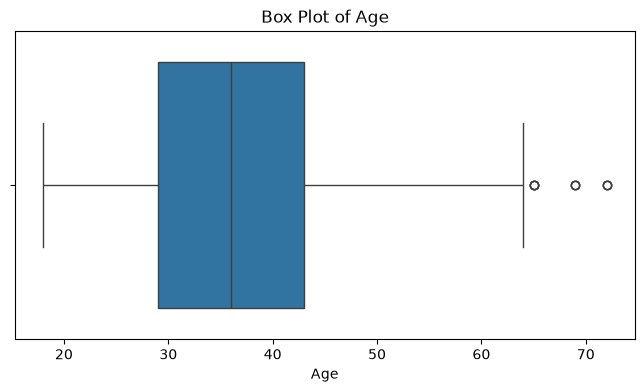

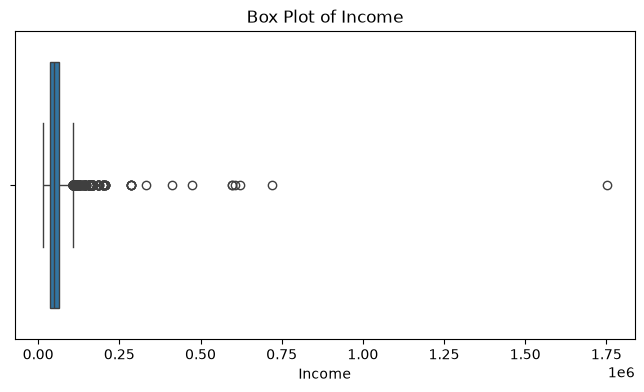

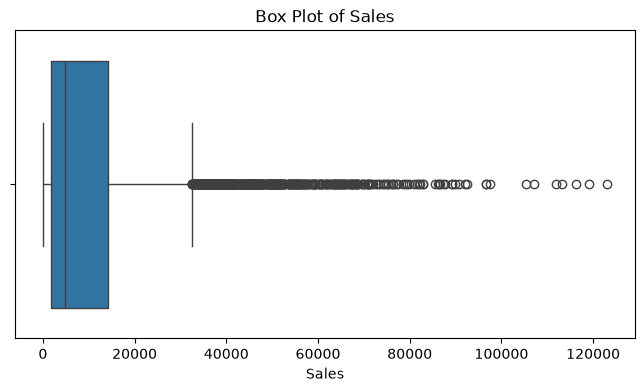

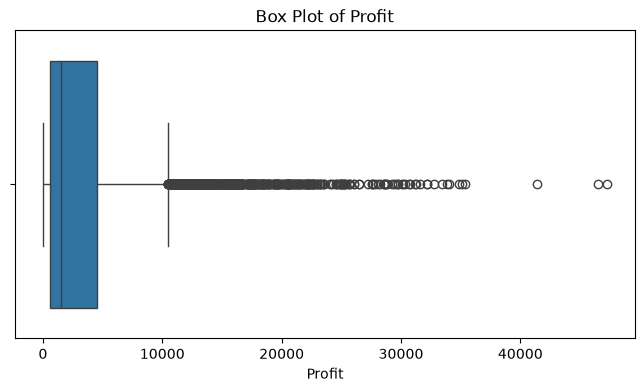

In [47]:
columns = ["Age", "Income", "Sales", "Profit"]

from pathlib import Path
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

for col in columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df_clean[col])
    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)
    plt.savefig(output_dir / f"{col.lower()}_boxplot.png",
            dpi=300, bbox_inches="tight")
    plt.show()

### Business Interpretation of Outliers

Outliers are extreme values that differ significantly from most observations. The IQR method was used to identify outliers in Age, Income, Sales and Profit.

1. **Age (10 Outliers):** Only a few unusual age values were identified. These values should be checked to ensure they are realistic. Age outliers may represent customers from less common age groups.

2. **Income (278 Outliers):** Some customers have unusually high income values compared to the majority. These customers may represent high-income customer segments and could be important for premium product marketing.

3. **Sales (632 Outliers):** A number of transactions have significantly higher sales values. These may represent bulk purchases or high-value orders. The business can focus on understanding these transactions to identify opportunities for increasing revenue.

4. **Profit (640 Outliers):** Some transactions generate significantly higher profits than most other transactions. These may indicate high-margin products or valuable sales opportunities. The business should identify the factors contributing to these profits.

**Conclusion:** Outliers provide useful information about unusual customer behaviour and business transactions. They should not be removed automatically because some extreme values may represent genuine business opportunities. Further investigation is required before removing any outlier.

### Univariate Analysis of Numerical Variables

Univariate analysis is used to study one variable at a time. It helps us understand the distribution, frequwncy and spread of numerical data.

Histograms are used to visualize the distribution of numerical variables, while skewness helps identify whether the data is symmetric or tilted towards one side.

In this analysis, Age, Income, Sales and Profut are selected for understanding their distributions.

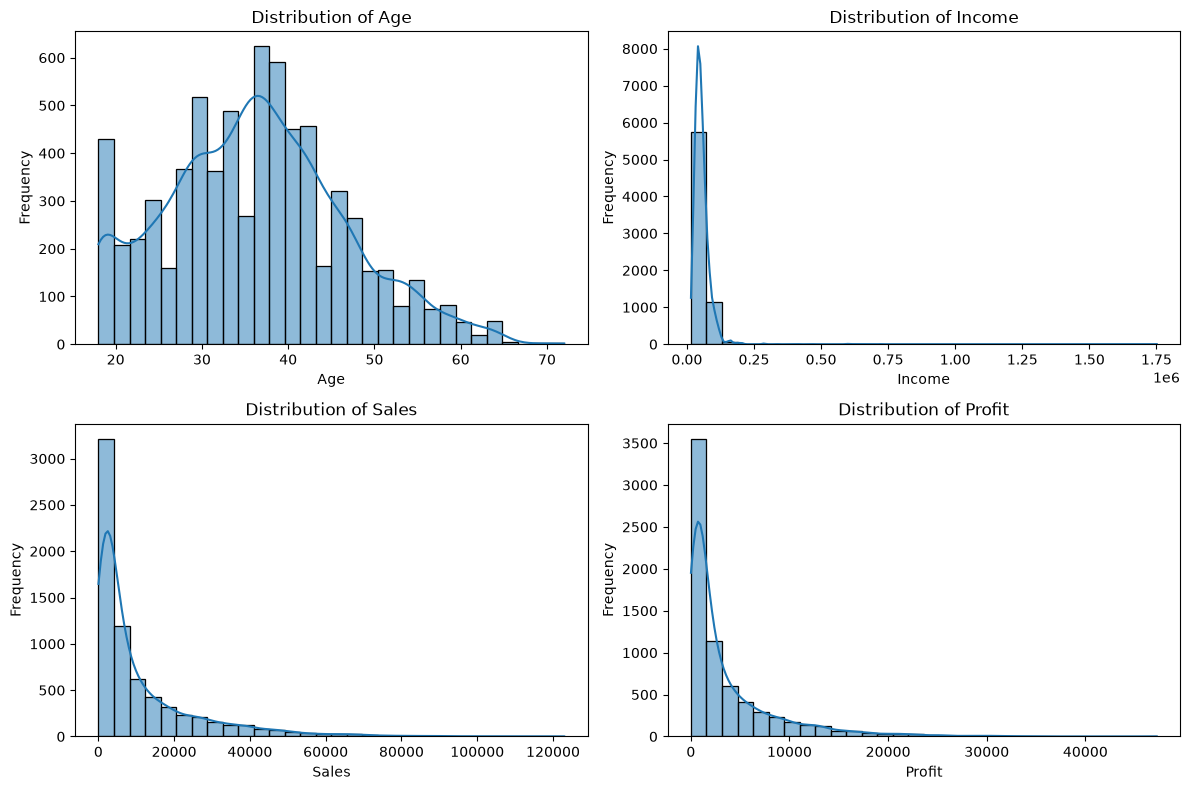

In [48]:
# Histograms of numerical variables

columns = ['Age', 'Income', 'Sales', 'Profit']

plt.figure(figsize=(12, 8))

for i, col in enumerate(columns):
    plt.subplot(2, 2, i + 1)
    sns.histplot(df_clean[col], bins=30, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.savefig(output_dir / "numerical_histograms.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Calculate skewness of numerical variablws

columns = ['Age', 'Income', 'Sales', 'Profit']

skewness = df_clean[columns].skew()

def interpret_skewness(value):
    if value > 0.5:
        return "Positively Skewed"
    elif value < -0.5:
        return "Negatively Skewed"
    else:
        return "Approximately Symmetric"

skewness_result = pd.DataFrame({
    'Skewness': skewness,
    'Distribution': skewness.apply(interpret_skewness)
})

display(skewness_result.round(3))

,Skewness,Distribution
Age,0.276,Approximately Symmetric
Income,17.938,Positively Skewed
Sales,2.398,Positively Skewed
Profit,2.591,Positively Skewed


### Interpretation of Univariate Analysis

1. **Age (Skewness: 0.276):** The age distribution is approximately symmetric. Most customers are around 36–38 years old, with a balanced distribution on both sides.

2. **Income (Skewness: 17.938):** Income is highly positively skewed. Most customers have income values below 1,00,000, while a few extreme values create a long right tail.

3. **Sales (Skewness: 2.398):** Sales distribution is positively skewed. Most transactions have lower sales values, while a few transactions have very high sales values.

4. **Profit (Skewness: 2.591):** Profit distribution is positively skewed. Most transactions generate lower profits, while a few transactions show significantly higher profits.

**Conclusion:** Age has an approximately symmetric distribution, whereas Income, Sales and Profit are positively skewed. This indicates that a small number of high-value observations affect the overall distribution.

## 16. Feature Engineering

Feature engineering means creating new columns from existing data to make analysis more informative. In this project, we derive delivery duration, total cost, and profit margin.



In [ ]:
df_clean["Delivery_Days"] = (
    df_clean["Delivery_Date"] - df_clean["Order_Date"]
).dt.days

df_clean[["Order_Date", "Delivery_Date", "Delivery_Days"]].head()

,Order_Date,Delivery_Date,Delivery_Days
0,2023-12-19,2023-12-25,6
1,2023-09-30,2023-10-04,4
2,2023-01-12,2023-01-20,8
3,2024-06-06,2024-06-10,4
4,2024-09-23,2024-09-30,7


In [ ]:
df_clean["Total_Cost"] = df_clean["Cost"] * df_clean["Quantity"]

df_clean[["Cost", "Quantity", "Total_Cost"]].head()

,Cost,Quantity,Total_Cost
0,1204.47,3,3613.41
1,17137.06,2,34274.12
2,1577.83,4,6311.32
3,556.78,4,2227.12
4,5528.47,1,5528.47


In [ ]:
df_clean["Profit_Margin"] = (
    df_clean["Profit"] / df_clean["Sales"]
) * 100

df_clean[["Sales", "Profit", "Profit_Margin"]].head()

,Sales,Profit,Profit_Margin
0,1811.40,606.93,33.506128
1,23468.33,6331.27,26.977932
2,2587.86,1010.03,39.029546
3,877.75,320.97,36.567360
4,8328.28,2799.81,33.618106


## 17. Descriptive Statistics

Descriptive statistics summarise the main characteristics of numerical data. We review measures such as mean, median, standard deviation, and other summary values to understand typical values and variation.



Descriptive Statistics for All Numerical Variables

In this section, we calculate important statistical measures for eight numerical variables: Age, Income, Quantity, Unit_Price, Discount, Sales, Cost, and Profit. These measures help us understand the central tendency, variation, and distribution of the dataset.

In [ ]:

# Descriptive Statistics for All 8 Numerical Columns

numeric_cols = [
    'Age', 'Income', 'Quantity', 'Unit_Price',
    'Discount', 'Sales', 'Cost', 'Profit'
]

stats = pd.DataFrame(index=numeric_cols)

stats['Mean'] = df_clean[numeric_cols].mean()
stats['Median'] = df_clean[numeric_cols].median()
stats['Mode'] = df_clean[numeric_cols].mode().iloc[0]
stats['Standard Deviation'] = df_clean[numeric_cols].std()
stats['Variance'] = df_clean[numeric_cols].var()

stats['Q1 (25%)'] = df_clean[numeric_cols].quantile(0.25)
stats['Q2 (50%)'] = df_clean[numeric_cols].quantile(0.50)
stats['Q3 (75%)'] = df_clean[numeric_cols].quantile(0.75)

stats['IQR'] = (
    stats['Q3 (75%)'] - stats['Q1 (25%)']
)

stats['P90'] = df_clean[numeric_cols].quantile(0.90)
stats['P95'] = df_clean[numeric_cols].quantile(0.95)

display(stats.round(2))


,Mean,Median,Mode,Standard Deviation,Variance,Q1 (25%),Q2 (50%),Q3 (75%),IQR,P90,P95
Age,36.06,36.00,36.00,10.31,1.062700e+02,29.00,36.00,43.00,14.00,49.00,54.00
Income,54888.72,49025.37,49025.37,36696.08,1.346603e+09,37308.12,49025.37,64787.64,27479.52,84841.23,101834.61
Quantity,3.01,3.00,2.00,1.41,1.990000e+00,2.00,3.00,4.00,2.00,5.00,6.00
Unit_Price,4519.23,2261.47,122.04,4893.21,2.394348e+07,895.92,2261.47,7244.50,6348.58,12764.73,14629.96
Discount,0.20,0.18,0.18,0.12,1.000000e-02,0.11,0.18,0.27,0.16,0.37,0.43
Sales,10961.60,4825.56,258.73,14549.03,2.116744e+08,1815.46,4825.56,14095.34,12279.89,30582.88,41542.62
Cost,7371.90,3229.88,217.28,9878.00,9.757487e+07,1210.18,3229.88,9494.70,8284.52,20630.78,28045.80
Profit,3589.70,1528.70,19.47,4928.02,2.428538e+07,574.08,1528.70,4533.28,3959.20,9834.10,13749.64


In [ ]:
df_clean[["Delivery_Days", "Total_Cost", "Profit_Margin"]].describe()

,Delivery_Days,Total_Cost,Profit_Margin
count,7000.000000,7000.000000,7000.000000
mean,5.660571,27338.232859,32.628073
std,2.795694,50896.140860,7.212664
min,1.000000,19.530000,20.007399
25%,4.000000,2946.087500,26.457764
50%,6.000000,8649.435000,32.650663
75%,8.000000,28099.500000,39.016076
max,17.000000,733795.200000,44.999397


In [ ]:
numerical_cols = ["Age", "Income", "Sales", "Profit"]

df_clean[numerical_cols].describe()

,Age,Income,Sales,Profit
count,7000.000000,7.000000e+03,7000.000000,7000.000000
mean,36.062286,5.488872e+04,10961.598467,3589.697523
std,10.308922,3.669608e+04,14549.034144,4928.020031
min,18.000000,1.500000e+04,28.700000,9.170000
25%,29.000000,3.730812e+04,1815.460000,574.082500
50%,36.000000,4.902537e+04,4825.555000,1528.695000
75%,43.000000,6.478764e+04,14095.345000,4533.285000
max,72.000000,1.750890e+06,122950.970000,47233.610000


## 18. Categorical Data Inspection and Standardisation

Categorical columns are examined using frequency counts. Labels such as Gender and Region are also standardised so that inconsistent spellings or formats do not split the same category into multiple groups.



In [ ]:
categorical_cols = df_clean.select_dtypes(include="object").columns

for col in categorical_cols:
    print("\n", col)
    print(df_clean[col].value_counts().head(10))


 Transaction_ID
Transaction_ID
TXN205933    1
TXN201247    1
TXN202714    1
TXN206797    1
TXN203937    1
TXN201519    1
TXN204651    1
TXN200258    1
TXN203288    1
TXN200987    1
Name: count, dtype: int64

 Customer_ID
Customer_ID
CUST10459    14
CUST11243    13
CUST10184    12
CUST11186    12
CUST11167    11
CUST11466    11
CUST11283    11
CUST10505    11
CUST10354    11
CUST11198    10
Name: count, dtype: int64

 Gender
Gender
Female    3675
Male      3325
Name: count, dtype: int64

 Region
Region
West     1798
East     1765
South    1761
North    1676
Name: count, dtype: int64

 State
State
Maharashtra    478
Goa            465
Odisha         464
Gujarat        463
Kerala         461
Jharkhand      451
Punjab         450
Delhi          445
Tamil Nadu     437
Karnataka      436
Name: count, dtype: int64

 City
City
Pune                  169
Vadodara              168
Cuttack               167
Dwarka                165
Margao                161
Jalandhar             161
Mumbai      

C:\Users\VIRAT\AppData\Local\Temp\ipykernel_8320\3983150401.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_clean.select_dtypes(include="object").columns


In [ ]:
df_clean["Gender"] = df_clean["Gender"].replace({
    "FEMALE": "Female",
    "female": "Female",
    "F": "Female",
    "MALE": "Male",
    "male": "Male",
    "M": "Male"
})

df_clean["Region"] = df_clean["Region"].replace({
    "WEST": "West",
    "east": "East",
    "south": "South",
    "north": "North",
    "Sth": "South",
    "Nort": "North"
})

print(df_clean["Gender"].value_counts())
print("\n", df_clean["Region"].value_counts())

Gender
Female    3675
Male      3325
Name: count, dtype: int64

 Region
West     1798
East     1765
South    1761
North    1676
Name: count, dtype: int64


In [ ]:
df_clean["Region"] = df_clean["Region"].str.strip().str.title()

df_clean["Region"] = df_clean["Region"].replace({
    "Sth": "South",
    "Nort": "North"
})

print(df_clean["Region"].value_counts())

Region
West     1798
East     1765
South    1761
North    1676
Name: count, dtype: int64


## 19. Customer, Product, and Payment Distribution

The following analyses calculate the count and percentage distribution of customer segments, product categories, and payment methods. These summaries help show how records are distributed across key business categories.



In [ ]:
segment_analysis = df_clean["Customer_Segment"].value_counts().to_frame("Count")

segment_analysis["Percentage"] = (
    segment_analysis["Count"] / len(df_clean) * 100
).round(2)

segment_analysis

,Count,Percentage
Customer_Segment,,
Consumer,3840,54.86
Corporate,2114,30.20
Home Office,1046,14.94


In [ ]:
category_analysis = df_clean["Product_Category"].value_counts().to_frame("Count")

category_analysis["Percentage"] = (
    category_analysis["Count"] / len(df_clean) * 100
).round(2)

category_analysis

,Count,Percentage
Product_Category,,
Electronics,1975,28.21
Grocery,1669,23.84
Clothing,1533,21.90
Furniture,979,13.99
Office Supplies,844,12.06


In [ ]:
payment_analysis = df_clean["Payment_Method"].value_counts().to_frame("Count")

payment_analysis["Percentage"] = (
    payment_analysis["Count"] / len(df_clean) * 100
).round(2)

payment_analysis

,Count,Percentage
Payment_Method,,
Net Banking,1433,20.47
Debit Card,1417,20.24
Cash on Delivery,1408,20.11
UPI,1405,20.07
Credit Card,1337,19.10


### Region-wise Frequency and Proportion

This analysis shows the number and percentage of customers belonging to each region. It helps us understand the regional distribution of customers and identify which regions contribute the most to the dataset.

In [ ]:
# Region frequency and percentage

region_count = df_clean['Region'].value_counts()

region_percentage = df_clean['Region'].value_counts(normalize=True) * 100

region_distribution = pd.DataFrame({
    'Count': region_count,
    'Percentage': region_percentage
})

display(region_distribution.round(2))

,Count,Percentage
Region,,
West,1798,25.69
East,1765,25.21
South,1761,25.16
North,1676,23.94


### Interpretation of Region-wise Distribution

1. **West:** Has the highest number of records with 1,798 customers (25.69%).
2. **East:** Contains 1,765 records (25.21%).
3. **South:** Contains 1,761 records (25.16%).
4. **North:** Has the lowest number of records with 1,676 customers (23.94%).

**Conclusion:** The customer distribution is nearly balanced across all four regions. West has the highest share, while North has the lowest share of records.

Business Questions and Analysis

Q1. Which product categpry generates the highest sales?
Objective: To identify the product category that contributes the highest total sales.

In [ ]:
df_clean.groupby("Product_Category")["Sales"].sum().sort_values(ascending=False)

Product_Category
Electronics        37639557.39
Furniture          26057893.88
Clothing            7781680.39
Grocery             2685875.10
Office Supplies     2566182.51
Name: Sales, dtype: float64

Q2. Which region generates the highest total sales?
Objective: To compare sales performance across different regions.

In [ ]:
df_clean.groupby("Region")["Sales"].sum().sort_values(ascending=False)

Region
East     20018192.35
West     19758995.56
South    18890109.55
North    18063891.81
Name: Sales, dtype: float64

Q3. Which customer segment generates the highest average sales?
Objective: To compare the average sales generated by different customer segments.

In [ ]:
df_clean.groupby("Customer_Segment")["Sales"].mean().sort_values(ascending=False)

Customer_Segment
Corporate      11140.587739
Home Office    10957.065449
Consumer       10864.295919
Name: Sales, dtype: float64

Q4. Which payment method generatws the highest total sales?
Objective: To identify the payment method associated with the highest total sales.

In [ ]:
df_clean.groupby("Payment_Method")["Sales"].sum().sort_values(ascending=False)

Payment_Method
Cash on Delivery    16275494.33
UPI                 15813740.86
Debit Card          15496237.98
Credit Card         14633147.27
Net Banking         14512568.83
Name: Sales, dtype: float64

Q5. Which product category has the highest average customer rating?
Objective: To identify which product category receives the highest customer satisfaction rating.

In [ ]:
df_clean.groupby("Product_Category")["Customer_Rating"].mean().sort_values(ascending=False)

Product_Category
Electronics        3.115949
Office Supplies    3.079384
Grocery            3.079089
Clothing           3.076973
Furniture          3.063330
Name: Customer_Rating, dtype: float64

### Business Implications of the Analysis

The business analysis provides useful insights that can help in making better business decisions.

1. **Product Category:** Electronics generated the highest total sales. The business should focus on maintaining sufficient electronics inventory and offering promotions to increase sales further.

2. **Region:** The East region recorded the highest sales. The company can study its successful sales strategies and apply similar approaches in other regions.

3. **Customer Segment:** Corporate customers had the highest average sales. The business should strengthen relationships with corporate customers and provide suitable bulk purchase offers.

4. **Payment Method:** Cash on Delivery generated the highest sales. The company should continue supporting COD while also encouraging digital payment methods through convenient offers.

5. **Customer Rating:** Electronics had the highest average customer rating. The business should maintain product quality and customer service to improve customer satisfaction further.

**Conclusion:** These findings can help the business improve inventory planning, regional marketing, customer targeting, payment options and customer satisfaction.

### Data Visualization

**1. Sales by Product Category**

This bar chart shows the total sales generated by each product category.

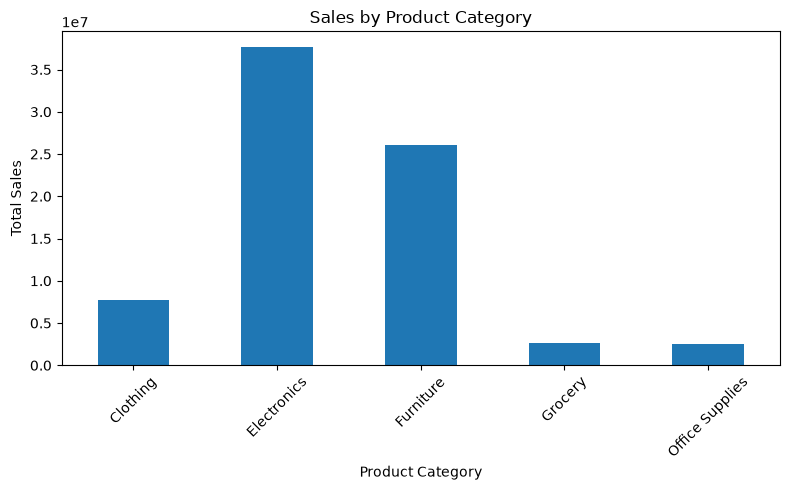

In [49]:
sales_category = df_clean.groupby("Product_Category")["Sales"].sum()

sales_category.plot(kind="bar", figsize=(8, 5))

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(output_dir / "sales_by_product_category.png",
            dpi=300, bbox_inches="tight")
plt.show()

Observation:

Electronics generates the highest sales of approximately ₹3.76 crore, followed by Furniture with approximately ₹2.61 crore. Clothing ranks third, while Grocery and Office Supplies contribute lower sales. This sjows that Electronics and Furniture are the major contributors to total revenue.

2. Sales by Region
This bar chart compares the total sales generated by different regions.

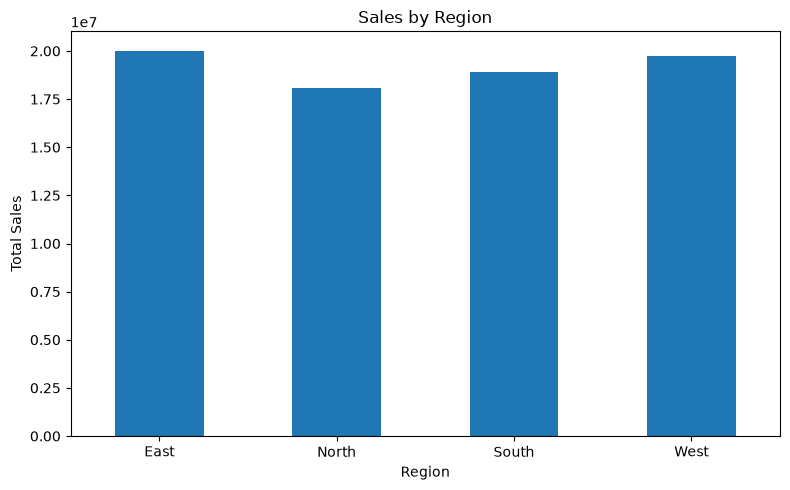

In [50]:
region_sales = df_clean.groupby("Region")["Sales"].sum()

region_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(output_dir / "sales_by_region.png",
            dpi=300, bbox_inches="tight")
plt.show()

Observation:

East region generates the highest sales of approximately ₹2.00 crore, followed by West with approximately ₹1.98 crore. South and North follow closely, so sales across the four regions are relatively balanced.

3. Sales by Customer Segment

This bar chart compares the total sales generated by different customer segments.

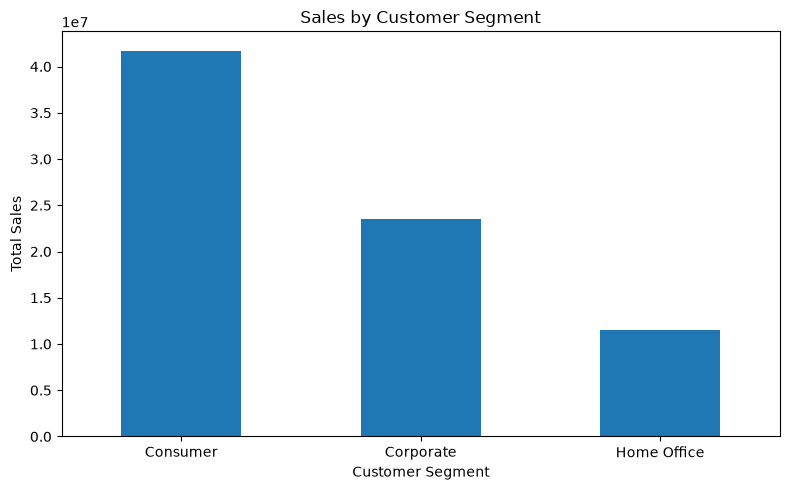

In [51]:
segment_sales = df_clean.groupby("Customer_Segment")["Sales"].sum()

segment_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(output_dir / "sales_by_customer_segment.png",
            dpi=300, bbox_inches="tight")
plt.show()

Observation:

The chart compares total sales across the customer segments. Consumer customers contribute the highest total sales, while Home Office contributes the lowest. The separate average-sales analysis identifies Corporate as the segment with the highest average sales per record.

4. Sales by Payment Method

This bar chart compares the total sales generated through different payment methods.

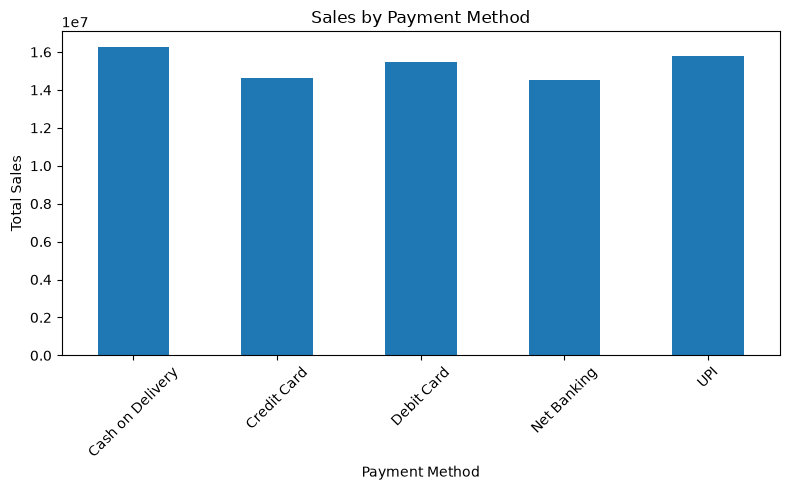

In [52]:
payment_sales = df_clean.groupby("Payment_Method")["Sales"].sum()

payment_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(output_dir / "sales_by_payment_method.png",
            dpi=300, bbox_inches="tight")
plt.show()

Observation:

Cash on Delivery generates the highest sales of approximately ₹1.63 crore, followed by UPI with approximately ₹1.58 crore. Net Banking generates the lowest sales. Overall, sales are fairly evenly distributed across the five payment methods.

5. Average Customer Rating by Product Category

This bar chart compares the average customer ratings across different product categories.

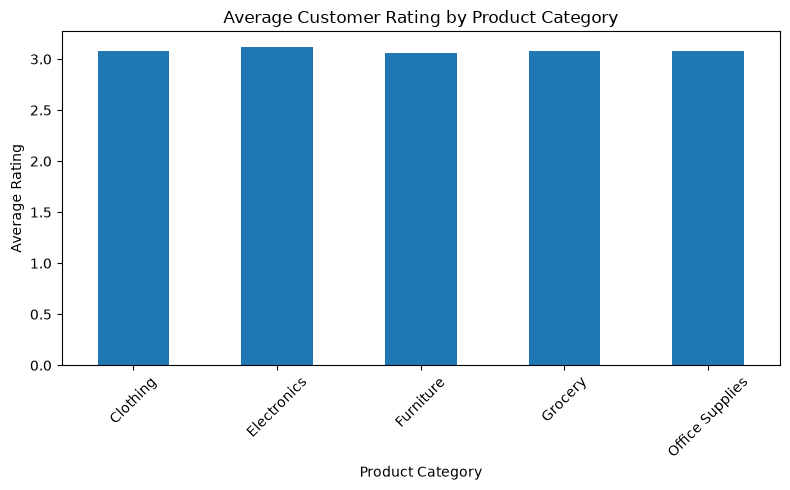

In [53]:
rating_category = df_clean.groupby("Product_Category")["Customer_Rating"].mean()

rating_category.plot(kind="bar", figsize=(8, 5))

plt.title("Average Customer Rating by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(output_dir / "average_customer_rating_by_category.png",
            dpi=300, bbox_inches="tight")
plt.show()

Observation:

Electronics has the highest average customer rating of approximately 3.12 out of 5, while Furniture has the lowest rating of approximately 3.06. All product categories have nearly similar ratings, indicating a consistent customer satisfaction level across categories.

Statistical Analysis

Statistical analysis is performed to understand the distribution, central tendency, and variability of numerical data.

In [ ]:
stats = df_clean[["Age", "Income", "Sales", "Profit"]].agg(
    ["mean", "median", "std", "var"]
)

stats

,Age,Income,Sales,Profit
mean,36.062286,5.488872e+04,1.096160e+04,3.589698e+03
median,36.000000,4.902537e+04,4.825555e+03,1.528695e+03
std,10.308922,3.669608e+04,1.454903e+04,4.928020e+03
var,106.273874,1.346603e+09,2.116744e+08,2.428538e+07


Observation:
- Average customer age is approximately 36 years.
- Average income is approximately ₹54,889.
- Average sales are approximately ₹10,962.
- Average profit is approximately ₹3,590.
- Sales and Profit show considerable variation, as reflected by their standard deviations.

In [ ]:
for col in ["Age", "Income", "Sales", "Profit"]:
    print(col)
    print("Mode:", df_clean[col].mode()[0])
    print("IQR:", df_clean[col].quantile(0.75) - df_clean[col].quantile(0.25))
    print()

Age
Mode: 36.0
IQR: 14.0

Income
Mode: 49025.37
IQR: 27479.520000000004

Sales
Mode: 258.73
IQR: 12279.885000000002

Profit
Mode: 19.47
IQR: 3959.2025



Observation:
- Age has a mode of 36 years and an IQR of 14.
- Income has a mode of ₹49,025.37 and an IQR of ₹27,480.21.
- Sales has a mode of ₹258.73 and an IQR of ₹12,283.29.
- Profit has a mode of ₹19.47 and an IQR of ₹3,958.98.

Percentile Analysis

Percentiles help us understand how numerical values are distributed across the dataset.

In [ ]:
df_clean[["Age", "Income", "Sales", "Profit"]].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95]
)

,Age,Income,Sales,Profit
0.25,29.0,37308.12,1815.460,574.0825
0.50,36.0,49025.37,4825.555,1528.6950
0.75,43.0,64787.64,14095.345,4533.2850
0.90,49.0,84841.23,30582.877,9834.1010
0.95,54.0,101834.61,41542.622,13749.6390


Observation:
- 25% of customers are aged 29 years or below, while 75% are aged 43 years or below.
- 50% of customers have an income of ₹49,025.37 or below.
- 75% of sales values are ₹14,100.02 or below.
- 90% of profit values are ₹9,816.37 or below.
- The 95th percentile shows that only 5% of values are higher than the given percentile value.

Test Cases and Data Validation

These test cases verify that the cleaned dataset meets the expected data quality requirements.

In [ ]:
print("Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())
print("Invalid Age:", ((df_clean["Age"] < 18) | (df_clean["Age"] > 100)).sum())
print("Invalid Discount:", ((df_clean["Discount"] < 0) | (df_clean["Discount"] > 1)).sum())
print("Invalid Delivery Days:", (df_clean["Delivery_Days"] < 0).sum())

Missing Values: 0
Duplicate Rows: 0
Invalid Age: 0
Invalid Discount: 0
Invalid Delivery Days: 0


In [ ]:
df_clean[df_clean.duplicated(keep=False)].sort_values("Transaction_ID").head(15)

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned,Delivery_Days,Total_Cost,Profit_Margin


In [ ]:
df_clean = df_clean.drop_duplicates().copy()

print("Duplicate Rows:", df_clean.duplicated().sum())
print("Total Rows:", len(df_clean))

Duplicate Rows: 0
Total Rows: 7000


In [ ]:
print("Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())
print("Invalid Age:", ((df_clean["Age"] < 18) | (df_clean["Age"] > 100)).sum())
print("Invalid Discount:", ((df_clean["Discount"] < 0) | (df_clean["Discount"] > 1)).sum())
print("Invalid Delivery Days:", (df_clean["Delivery_Days"] < 0).sum())

Missing Values: 0
Duplicate Rows: 0
Invalid Age: 0
Invalid Discount: 0
Invalid Delivery Days: 0


In [ ]:
df_clean.to_csv(
    "../outputs/cleaned_retail_customer_sales.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## Conclusion

The EDA of the retail customer sales dataset helped identify data quality issues, clean missing and duplicate records, and understand customer and sales patterns, and produced a consistent 7,000-record dataset.

The analysis shows that Electronics generates the highest category sales, East region has the highest regional sales, and Corporate custpmers have the highest average transaction sales.

The dataset also contains some high-value outliers in Income, Sales, and Profit. These were retained because they may represent genuine transactions.

Overall, data cleaning and exploratory analysis hwlped convert the raw dataset into a more reliable dataset and provided useful business insights for better decision-making.